# ``meshlab`` - Tutorial 1

**Boundary layers around a circle**


## 1. Import packages
---


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import insert_contour, initialize_front, compute_normals, advance_front
from meshlab.utils import plot_mesh

## 2. Geometries definition
---


Circle


In [2]:
# Geometric parameters
radius = 1.0
num_points = 64

# Counter-clockwise direction
angles = np.linspace(0.0, 2.0 * np.pi, num_points, endpoint=False)
points = radius * np.column_stack((np.cos(angles), np.sin(angles)))

# Close curve
points = np.vstack((points, points[0]))

# Define contour
circle = Contour("body", [Curve("wall", points)])

## 3. Creating mesh surfaces
---


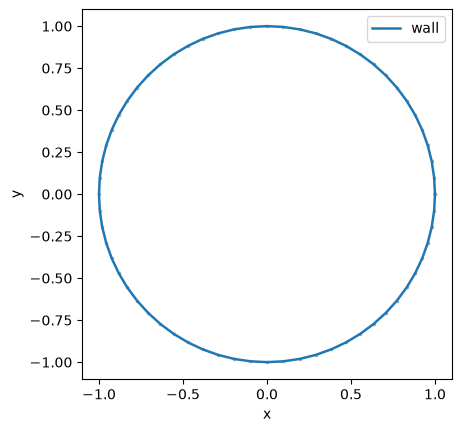

In [3]:
# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contour
insert_contour(mesh, circle)

_ = plot_mesh(mesh)

## 4. Initialize front
---


In [4]:
# Layer parameters
height = 0.08
growth_rate = 1.15
additional_layers = 5

# Front definition
front = Front("body_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

## 5. Growing boundary layers
---


First layer


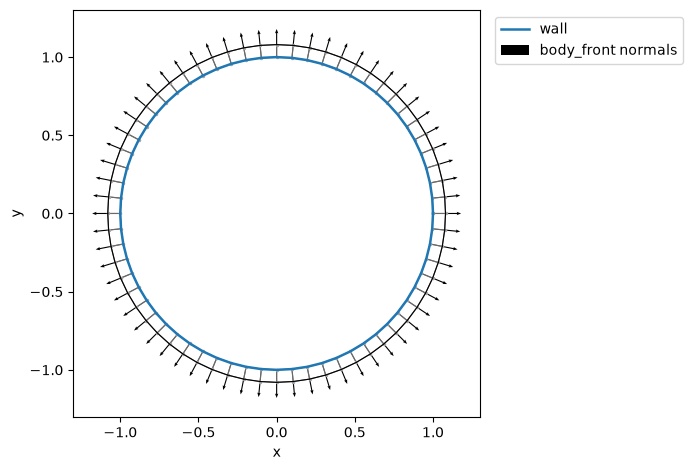

In [5]:
normals = compute_normals(mesh, front, method="central")
advance_front(mesh, front, normals, height)

normal_scale = 0.1
figure, ax = plot_mesh(mesh, normals=[(front, normals)], normal_scale=normal_scale, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

Second layer


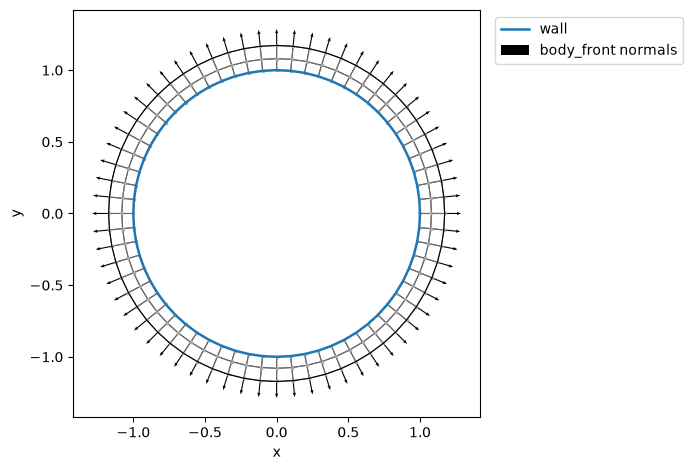

In [6]:
height *= growth_rate
normals = compute_normals(mesh, front, method="central")
advance_front(mesh, front, normals, height)

normal_scale *= growth_rate
figure, ax = plot_mesh(mesh, normals=[(front, normals)], normal_scale=normal_scale, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

Third layer


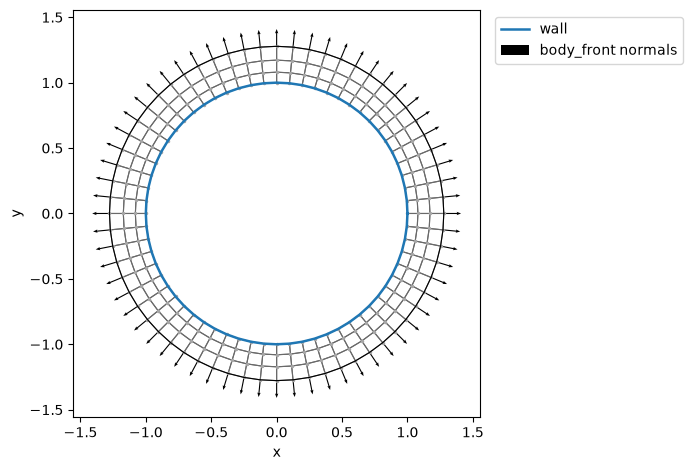

In [7]:
height *= growth_rate
normals = compute_normals(mesh, front, method="central")
advance_front(mesh, front, normals, height)

normal_scale *= growth_rate
figure, ax = plot_mesh(mesh, normals=[(front, normals)], normal_scale=normal_scale, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

Additional layers


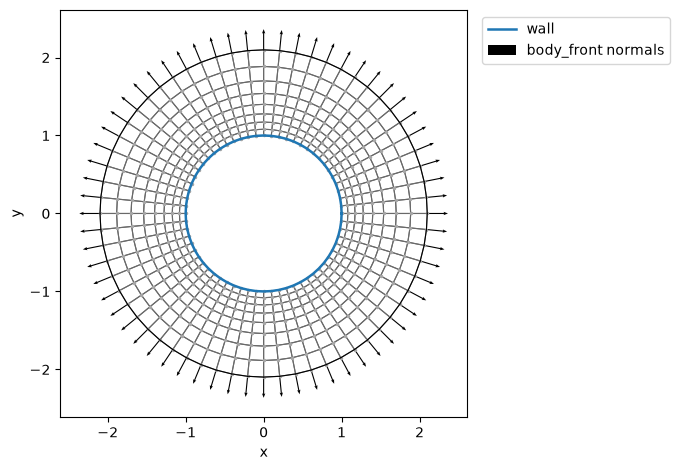

In [8]:
for _ in range(additional_layers):
    height *= growth_rate
    normals = compute_normals(mesh, front, method="central")
    advance_front(mesh, front, normals, height)
    normal_scale *= growth_rate

figure, ax = plot_mesh(mesh, normals=[(front, normals)], normal_scale=normal_scale, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## 6. Circular domain
---


In [9]:
# Geometric parameters
outer_radius = 3.5

# External contour in a clockwise direction
outer_angles = np.linspace(0.0, -2.0 * np.pi, num_points, endpoint=False)
outer_points = outer_radius * np.column_stack((np.cos(outer_angles), np.sin(outer_angles)))

# Close curve
outer_points = np.vstack((outer_points, outer_points[0]))

# Define and insert contour
outer_domain = Contour("outer_domain", [Curve("farfield", outer_points)])
insert_contour(mesh, outer_domain)

## 7. Visualize mesh
---


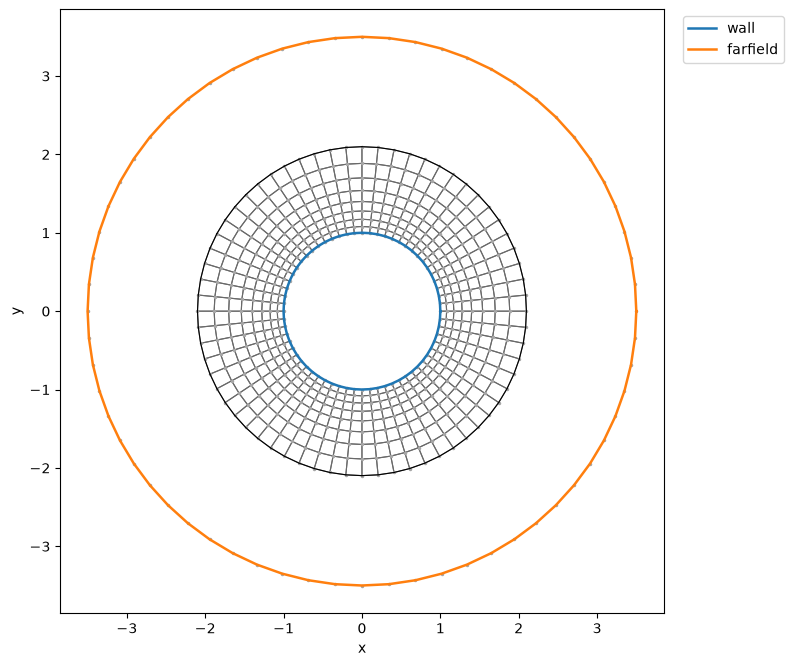

In [10]:
# The region between the layers and the outer domain remains unmeshed
figure, ax = plot_mesh(mesh, show=False)

figure.set_size_inches(8, 8)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()